---
## 1. Configuración e importación de los datos

### 1.1 Conectar Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 1.2 Rutas, clases y conteo de imágenes

In [ ]:
import os

# AJUSTA esta ruta a donde está tu dataset en Drive
RUTA_DATASET  = '/content/drive/MyDrive/IA2/Dataset - Rostros Masculinos/Train'

clases = ['Redondo', 'Rectangular', 'Ovalado', 'Cuadrado']
extensiones = ('.jpg', '.jpeg', '.png')

total = 0
for c in clases:
    ruta = os.path.join(RUTA_DATASET , c)
    n = len([f for f in os.listdir(ruta) if f.lower().endswith(extensiones)])
    total += n
    print(f'{c:12s} {n}')
print(f'{"TOTAL":12s} {total}')

Redondo      322
Rectangular  317
Ovalado      319
Cuadrado     323
TOTAL        1281


### 1.3 Muestras del dataset

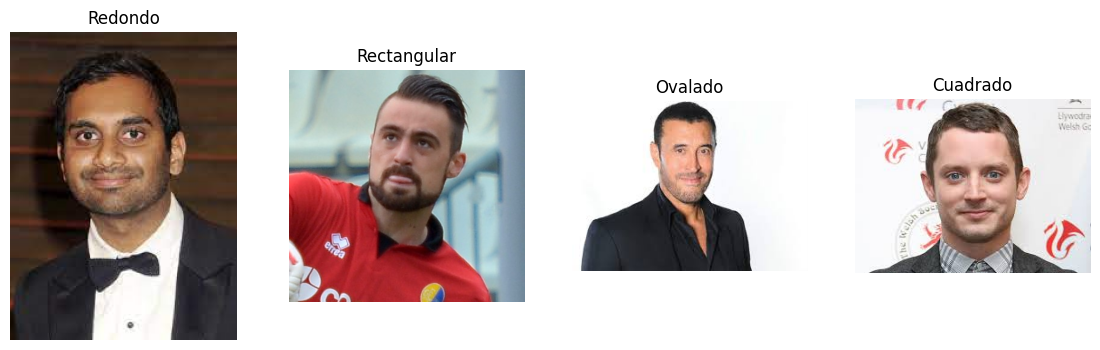

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(14, 4))
for i, nombre in enumerate(clases):
    ruta = os.path.join(RUTA_DATASET, nombre)
    archivos = [f for f in os.listdir(ruta) if f.lower().endswith(extensiones)]
    elegido = random.choice(archivos)
    imagen = Image.open(os.path.join(ruta, elegido))
    plt.subplot(1, 4, i + 1)
    plt.imshow(imagen)
    plt.title(nombre)
    plt.axis('off')
plt.show()

---
## 2. Detección y recorte de rostros

Las fotos incluyen torso, fondo y distintos encuadres. Para que Inception v3 se concentre en la forma del rostro, primero se **detecta** la cara con `dlib`, se recorta incluyendo frente y mentón, y se guarda en formato cuadrado de 299×299.

### 2.1 Instalar dlib

`dlib` es la librería que usa el repositorio original para detectar rostros.
[Repositorio](https://github.com/adonistio/inception-face-shape-classifier)

In [ ]:
!pip install dlib -q

### 2.2 Detector de rostros

`get_frontal_face_detector()` crea el detector de rostros frontales (HOG + SVM). Aquí se prueba en una imagen por clase: el cuadro verde es el rostro encontrado.

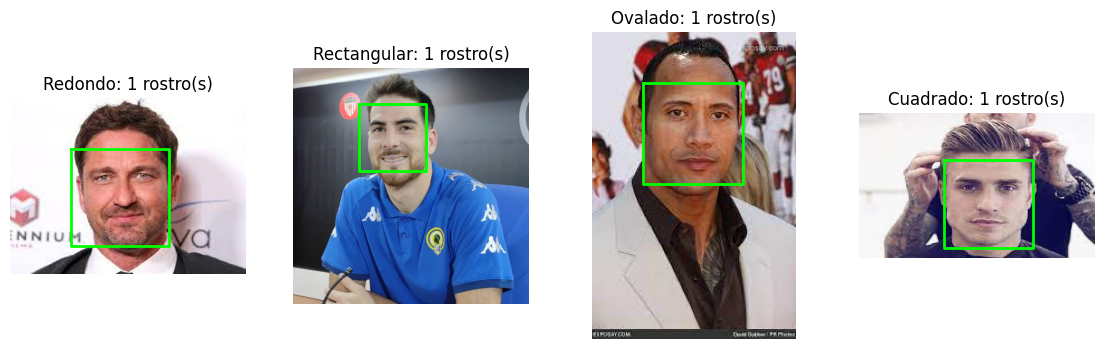

In [ ]:
import dlib
import numpy as np

detector = dlib.get_frontal_face_detector()

plt.figure(figsize=(14, 4))
for i, nombre in enumerate(clases):
    ruta = os.path.join(RUTA_DATASET, nombre)
    archivos = [f for f in os.listdir(ruta) if f.lower().endswith(extensiones)]
    elegido = random.choice(archivos)
    imagen = Image.open(os.path.join(ruta, elegido)).convert('RGB')
    arreglo = np.array(imagen)
    rostros = detector(arreglo, 1)
    plt.subplot(1, 4, i + 1)
    plt.imshow(arreglo)
    for r in rostros:
        xs = [r.left(), r.right(), r.right(), r.left(), r.left()]
        ys = [r.top(), r.top(), r.bottom(), r.bottom(), r.top()]
        plt.plot(xs, ys, color='lime', linewidth=2)
    plt.xlim(0, arreglo.shape[1])
    plt.ylim(arreglo.shape[0], 0)
    plt.title(nombre + ': ' + str(len(rostros)) + ' rostro(s)')
    plt.axis('off')
plt.show()

### 2.3 Funciones para ajustar la caja

In [ ]:
def ampliar_caja(r, ancho_img, alto_img):
    ancho = r.right() - r.left()
    alto = r.bottom() - r.top()
    x1 = max(0, int(r.left() - 0.15 * ancho))
    x2 = min(ancho_img, int(r.right() + 0.15 * ancho))
    y1 = max(0, int(r.top() - 0.5 * alto))
    y2 = min(alto_img, int(r.bottom() + 0.1 * alto))
    return x1, y1, x2, y2

def dibujar_caja(x1, y1, x2, y2, color):
    plt.plot([x1, x2, x2, x1, x1], [y1, y1, y2, y2, y1], color=color, linewidth=2)

### 2.4 Vista previa del recorte

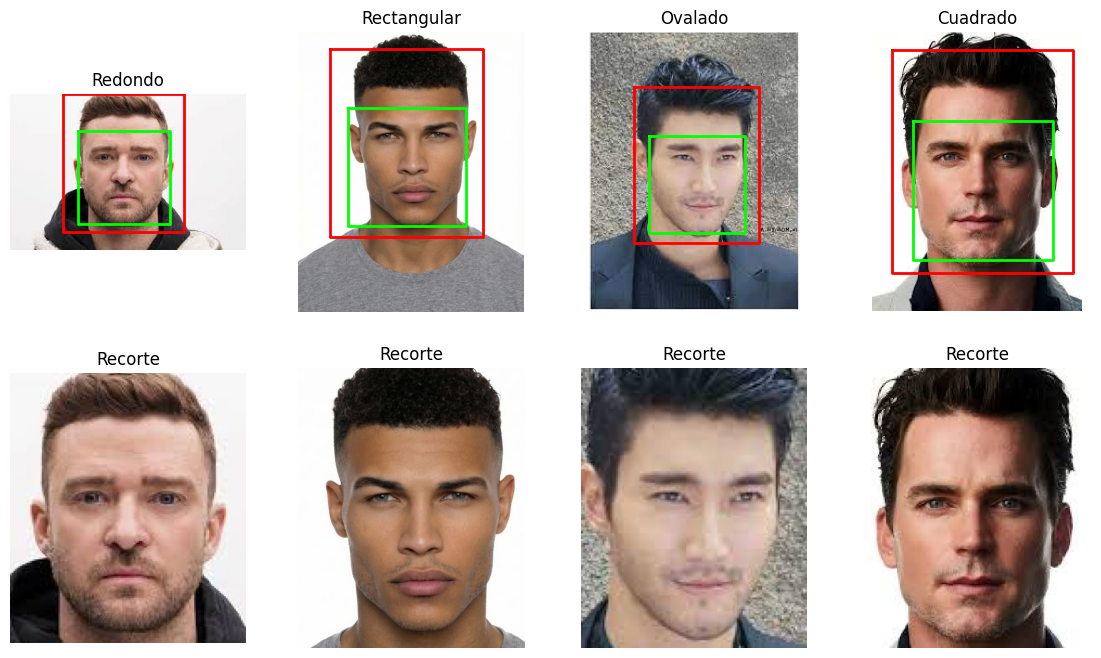

In [ ]:
plt.figure(figsize=(14, 8))
for i, nombre in enumerate(clases):
    ruta = os.path.join(RUTA_DATASET, nombre)
    archivos = [f for f in os.listdir(ruta) if f.lower().endswith(extensiones)]
    elegido = random.choice(archivos)
    arreglo = np.array(Image.open(os.path.join(ruta, elegido)).convert('RGB'))
    alto_img, ancho_img = arreglo.shape[0], arreglo.shape[1]
    rostros = detector(arreglo, 1)

    plt.subplot(2, 4, i + 1)
    plt.imshow(arreglo)
    plt.title(nombre)
    plt.axis('off')

    if len(rostros) > 0:
        r = rostros[0]
        dibujar_caja(r.left(), r.top(), r.right(), r.bottom(), 'lime')
        x1, y1, x2, y2 = ampliar_caja(r, ancho_img, alto_img)
        dibujar_caja(x1, y1, x2, y2, 'red')
        plt.xlim(0, ancho_img)
        plt.ylim(alto_img, 0)

        plt.subplot(2, 4, i + 5)
        plt.imshow(arreglo[y1:y2, x1:x2])
        plt.title('Recorte')
        plt.axis('off')
plt.show()

### 2.5 Recortar el conjunto Train

In [ ]:
from tqdm import tqdm
from PIL import ImageOps

RUTA_SALIDA = '/content/drive/MyDrive/IA2/Dataset - Rostros Masculinos/rostros_inception_train'
TAM = 299

def ampliar_caja(r, ancho_img, alto_img):
    ancho = r.right() - r.left()
    alto = r.bottom() - r.top()
    x1 = max(0, int(r.left() - 0.15 * ancho))
    x2 = min(ancho_img, int(r.right() + 0.15 * ancho))
    y1 = max(0, int(r.top() - 0.5 * alto))
    y2 = min(alto_img, int(r.bottom() + 0.15 * alto))
    return x1, y1, x2, y2

sin_rostro = {}
guardadas = {}

for nombre in clases:
    os.makedirs(os.path.join(RUTA_SALIDA, nombre), exist_ok=True)
    sin_rostro[nombre] = []
    guardadas[nombre] = 0
    carpeta = os.path.join(RUTA_DATASET, nombre)
    archivos = [f for f in os.listdir(carpeta) if f.lower().endswith(extensiones)]

    for archivo in tqdm(archivos, desc=nombre):
        try:
            imagen = Image.open(os.path.join(carpeta, archivo)).convert('RGB')
            arreglo = np.array(imagen)
            rostros = detector(arreglo, 1)

            if len(rostros) == 0:
                sin_rostro[nombre].append(archivo)
                continue

            r = max(rostros, key=lambda c: c.area())
            x1, y1, x2, y2 = ampliar_caja(r, imagen.width, imagen.height)
            cara = imagen.crop((x1, y1, x2, y2))
            cara = ImageOps.pad(cara, (TAM, TAM), color=(128, 128, 128))

            nombre_salida = os.path.splitext(archivo)[0] + '.jpg'
            cara.save(os.path.join(RUTA_SALIDA, nombre, nombre_salida))
            guardadas[nombre] = guardadas[nombre] + 1
        except Exception:
            sin_rostro[nombre].append(archivo)

print()
for nombre in clases:
    print(nombre, ': guardadas', guardadas[nombre], '| sin rostro o con error', len(sin_rostro[nombre]))

Cuadrado: 100%|██████████| 323/323 [01:40<00:00,  3.21it/s]


Redondo : guardadas 322 | sin rostro o con error 0
Rectangular : guardadas 316 | sin rostro o con error 1
Ovalado : guardadas 318 | sin rostro o con error 1
Cuadrado : guardadas 323 | sin rostro o con error 0


### 2.6 Recortar el conjunto Test

In [ ]:
RUTA_TEST = '/content/drive/MyDrive/IA2/Dataset - Rostros Masculinos/Test'
RUTA_SALIDA_TEST = '/content/drive/MyDrive/IA2/Dataset - Rostros Masculinos/rostros_inception_test'

for nombre in clases:
    ruta = os.path.join(RUTA_TEST, nombre)
    if os.path.isdir(ruta):
        print(nombre, '-> existe,', len(os.listdir(ruta)), 'archivos')
    else:
        print(nombre, '-> NO EXISTE, revisa el nombre')

sin_rostro_test = {}

for nombre in clases:
    os.makedirs(os.path.join(RUTA_SALIDA_TEST, nombre), exist_ok=True)
    sin_rostro_test[nombre] = []
    carpeta = os.path.join(RUTA_TEST, nombre)
    if not os.path.isdir(carpeta):
        continue
    archivos = [f for f in os.listdir(carpeta) if f.lower().endswith(extensiones)]

    for archivo in tqdm(archivos, desc=nombre):
        imagen = Image.open(os.path.join(carpeta, archivo)).convert('RGB')
        arreglo = np.array(imagen)
        rostros = detector(arreglo, 1)

        if len(rostros) == 0:
            sin_rostro_test[nombre].append(archivo)
            cara = imagen
        else:
            r = max(rostros, key=lambda c: c.area())
            x1, y1, x2, y2 = ampliar_caja(r, imagen.width, imagen.height)
            cara = imagen.crop((x1, y1, x2, y2))

        cara = ImageOps.pad(cara, (TAM, TAM), color=(128, 128, 128))
        nombre_salida = os.path.splitext(archivo)[0] + '.jpg'
        cara.save(os.path.join(RUTA_SALIDA_TEST, nombre, nombre_salida))

print()
for nombre in clases:
    print(nombre, ': sin rostro detectado', len(sin_rostro_test[nombre]))

Redondo -> existe, 83 archivos
Rectangular -> existe, 83 archivos
Ovalado -> existe, 81 archivos
Cuadrado -> existe, 80 archivos


Cuadrado: 100%|██████████| 80/80 [01:02<00:00,  1.28it/s]


Redondo : sin rostro detectado 0
Rectangular : sin rostro detectado 0
Ovalado : sin rostro detectado 0
Cuadrado : sin rostro detectado 0


---
## 3. Preparación de los datos

### 3.1 División en entrenamiento y validación

Se usa el 100% de `Train` recortado: **80% para entrenar y 20% para validar** (la validación sirve para vigilar el entrenamiento). `Test` queda aparte para la evaluación final.

In [ ]:
from sklearn.model_selection import train_test_split

rutas = []
etiquetas = []
for nombre in clases:
    carpeta = os.path.join(RUTA_SALIDA, nombre)
    for archivo in sorted(os.listdir(carpeta)):
        if archivo.lower().endswith(extensiones):
            rutas.append(os.path.join(carpeta, archivo))
            etiquetas.append(nombre)

print('Total de rostros Train:', len(rutas))

rutas_train, rutas_val, et_train, et_val = train_test_split(
    rutas, etiquetas, test_size=0.20, stratify=etiquetas, random_state=42)

print('Entrenamiento:', len(rutas_train))
print('Validación:', len(rutas_val))

Total de rostros Train: 1278
Entrenamiento: 1022
Validación: 256


### 3.2 Copiar entrenamiento y validación al disco local

Keras toma la etiqueta de cada imagen del nombre de su carpeta, así que se arma la estructura `train/` y `val/` con una subcarpeta por clase. Se guarda en `/content` (disco local de Colab) porque es más rápido que Drive. **Este disco se borra si Colab se reinicia**.

In [ ]:
import shutil

RUTA_SPLIT = '/content/dataset_split'

if os.path.exists(RUTA_SPLIT):
    shutil.rmtree(RUTA_SPLIT)

def copiar(lista_rutas, lista_etiquetas, subcarpeta):
    for ruta, etiqueta in zip(lista_rutas, lista_etiquetas):
        destino = os.path.join(RUTA_SPLIT, subcarpeta, etiqueta)
        os.makedirs(destino, exist_ok=True)
        shutil.copy(ruta, destino)

copiar(rutas_train, et_train, 'train')
copiar(rutas_val, et_val, 'val')

for subcarpeta in ['train', 'val']:
    print(subcarpeta)
    for nombre in clases:
        carpeta = os.path.join(RUTA_SPLIT, subcarpeta, nombre)
        print('  ', nombre, ':', len(os.listdir(carpeta)))

train
   Redondo : 258
   Rectangular : 253
   Ovalado : 254
   Cuadrado : 257
val
   Redondo : 64
   Rectangular : 63
   Ovalado : 64
   Cuadrado : 65


### 3.3 Copiar Test al disco local

Agrega la carpeta `test/` con los rostros recortados de `Test`, para tener las tres particiones con la misma estructura.

In [ ]:
for nombre in clases:
    origen = os.path.join(RUTA_SALIDA_TEST, nombre)
    destino = os.path.join(RUTA_SPLIT, 'test', nombre)
    os.makedirs(destino, exist_ok=True)
    for archivo in os.listdir(origen):
        shutil.copy(os.path.join(origen, archivo), destino)

for subcarpeta in ['train', 'val', 'test']:
    print(subcarpeta)
    for nombre in clases:
        carpeta = os.path.join(RUTA_SPLIT, subcarpeta, nombre)
        print('  ', nombre, ':', len(os.listdir(carpeta)))

train
   Redondo : 258
   Rectangular : 253
   Ovalado : 254
   Cuadrado : 257
val
   Redondo : 64
   Rectangular : 63
   Ovalado : 64
   Cuadrado : 65
test
   Redondo : 83
   Rectangular : 83
   Ovalado : 81
   Cuadrado : 80


### 3.4 Cargar los datos en Keras

`image_dataset_from_directory` lee las carpetas y entrega imágenes de 299×299 con su etiqueta, en lotes de 32. Las etiquetas se convierten a vectores de 4 posiciones (`categorical`) y `class_names=clases` fija el orden de las clases.

In [ ]:
import tensorflow as tf

TAM_IMG = (299, 299)
LOTE = 32

datos_train = tf.keras.utils.image_dataset_from_directory(
    os.path.join(RUTA_SPLIT, 'train'),
    label_mode='categorical',
    class_names=clases,
    image_size=TAM_IMG,
    batch_size=LOTE,
    shuffle=True,
    seed=42)

datos_val = tf.keras.utils.image_dataset_from_directory(
    os.path.join(RUTA_SPLIT, 'val'),
    label_mode='categorical',
    class_names=clases,
    image_size=TAM_IMG,
    batch_size=LOTE,
    shuffle=False)

datos_test = tf.keras.utils.image_dataset_from_directory(
    os.path.join(RUTA_SPLIT, 'test'),
    label_mode='categorical',
    class_names=clases,
    image_size=TAM_IMG,
    batch_size=LOTE,
    shuffle=False)

print(datos_train.class_names)

Found 1022 files belonging to 4 classes.
Found 256 files belonging to 4 classes.
Found 327 files belonging to 4 classes.
['Redondo', 'Rectangular', 'Ovalado', 'Cuadrado']


### 3.5 Aumento de datos

Con pocas imágenes, la red tiende a memorizarlas. El aumento de datos genera variaciones suaves en cada época (espejo horizontal, giro de hasta ~14° y zoom de hasta 10%) y se rellena con gris para mantener los bordes. Se evitan deformaciones fuertes para no alterar la forma del rostro.

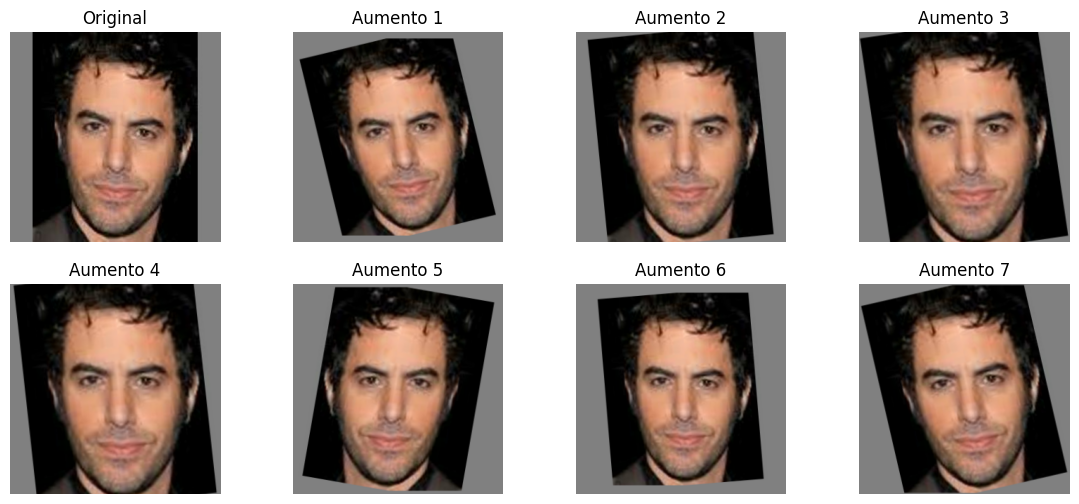

In [ ]:
aumento = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.04, fill_mode='constant', fill_value=128),
    tf.keras.layers.RandomZoom(0.1, fill_mode='constant', fill_value=128)
])

for imagenes, etiquetas in datos_train.take(1):
    imagen = imagenes[0]

plt.figure(figsize=(14, 6))
plt.subplot(2, 4, 1)
plt.imshow(imagen.numpy().astype('uint8'))
plt.title('Original')
plt.axis('off')

for i in range(7):
    modificada = aumento(tf.expand_dims(imagen, 0), training=True)
    plt.subplot(2, 4, i + 2)
    plt.imshow(modificada[0].numpy().astype('uint8'))
    plt.title('Aumento ' + str(i + 1))
    plt.axis('off')
plt.show()

---
## 4. Modelo base (Inception v3 congelada)

### 4.1 Cargar Inception v3 preentrenada

Se carga Inception v3 con los pesos de ImageNet, sin su capa final de 1000 categorías (`include_top=False`), y se **congela** (`trainable = False`) para que sus pesos no cambien. Funciona como extractor de características: convierte cada imagen en 2048 mapas de 8×8.

In [ ]:
base = tf.keras.applications.InceptionV3(
    weights='imagenet',
    include_top=False,
    input_shape=(299, 299, 3))

base.trainable = False

print('Capas de Inception v3:', len(base.layers))
print('Forma de la salida:', base.output_shape)

Capas de Inception v3: 311
Forma de la salida: (None, 8, 8, 2048)


### 4.2 Armar el modelo completo

Cadena de capas:
- entrada →
- aumento de datos →
- `preprocess_input` (pasa los píxeles a la escala -1 a 1 que usó Inception v3) →
- Inception v3 congelada →
- promedio global (2048 valores por imagen) →
- `Dropout` 30% →
- capa final `Dense` de 4 neuronas con softmax (una por forma de rostro).

Solo la capa final aprende: **8,196 parámetros entrenables** frente a 21.8 millones congelados.

In [ ]:
entrada = tf.keras.Input(shape=(299, 299, 3))
x = aumento(entrada)
x = tf.keras.applications.inception_v3.preprocess_input(x)
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
salida = tf.keras.layers.Dense(4, activation='softmax')(x)

modelo = tf.keras.Model(entrada, salida)

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy'])

modelo.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,810,980 (83.20 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

### 4.3 Entrenamiento

Entrena hasta 25 épocas. `ModelCheckpoint` guarda en Drive la mejor versión según `val_accuracy` y `EarlyStopping` detiene el entrenamiento si no mejora en 5 épocas, devolviendo los mejores pesos.

In [ ]:
print('GPU disponible:', tf.config.list_physical_devices('GPU'))

RUTA_MODELO = '/content/drive/MyDrive/IA2/inception_rostros.keras'

guardar_mejor = tf.keras.callbacks.ModelCheckpoint(
    RUTA_MODELO,
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1)

parar_temprano = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=5,
    restore_best_weights=True)

historial = modelo.fit(
    datos_train,
    validation_data=datos_val,
    epochs=25,
    callbacks=[guardar_mejor, parar_temprano])

GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Epoch 1/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.3435 - loss: 1.4129
Epoch 1: val_accuracy improved from None to 0.37891, saving model to /content/drive/MyDrive/IA2/inception_rostros.keras

Epoch 1: finished saving model to /content/drive/MyDrive/IA2/inception_rostros.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 26s 433ms/step - accuracy: 0.3444 - loss: 1.4021 - val_accuracy: 0.3789 - val_loss: 1.2712
Epoch 2/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.4240 - loss: 1.2878
Epoch 2: val_accuracy improved from 0.37891 to 0.42578, saving model to /content/drive/MyDrive/IA2/inception_rostros.keras

Epoch 2: finished saving model to /content/drive/MyDrive/IA2/inception_rostros.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 259ms/step - accuracy: 0.4168 - loss: 1.2882 - val_accuracy: 0.4258 - val_loss: 1.2104
Epoch 3/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.4550 - loss: 1.2436
Epoch 3: 

### 4.4 Curvas de entrenamiento

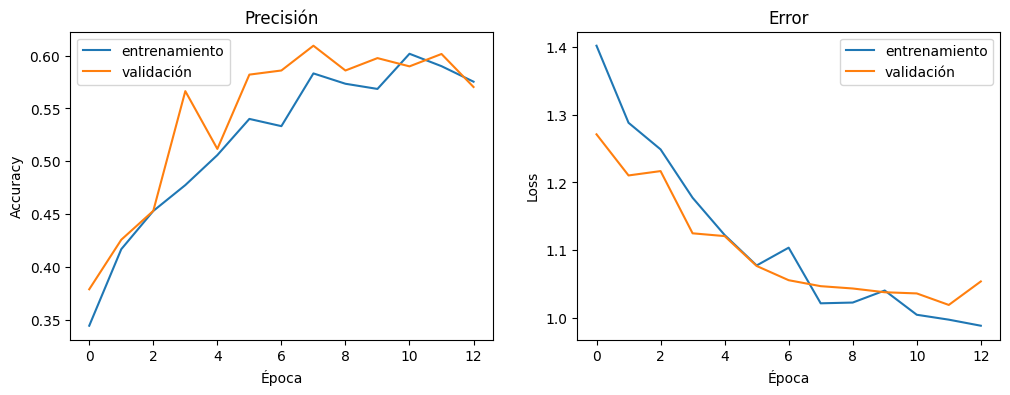

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(historial.history['accuracy'], label='entrenamiento')
plt.plot(historial.history['val_accuracy'], label='validación')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.title('Precisión')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(historial.history['loss'], label='entrenamiento')
plt.plot(historial.history['val_loss'], label='validación')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.title('Error')
plt.legend()

plt.show()

### 4.5 Evaluación del modelo base en Test

Calcula la precisión sobre las 327 imágenes de `Test`, que el modelo nunca vio, y guarda las predicciones (`y_pred`) junto con las clases reales (`y_real`).

In [ ]:
perdida_test, acc_test = modelo.evaluate(datos_test)
print('Accuracy en test:', round(acc_test, 4))

y_real = []
y_pred = []
for imagenes, etiquetas in datos_test:
    probabilidades = modelo.predict(imagenes, verbose=0)
    y_pred.extend(np.argmax(probabilidades, axis=1))
    y_real.extend(np.argmax(etiquetas.numpy(), axis=1))

print('Imágenes evaluadas:', len(y_real))

11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 268ms/step - accuracy: 0.3761 - loss: 1.4345
Accuracy en test: 0.3761
Imágenes evaluadas: 327


### 4.6 Matriz de confusión del modelo base


              precision    recall  f1-score   support

     Redondo      0.651     0.337     0.444        83
 Rectangular      0.343     0.554     0.424        83
     Ovalado      0.298     0.444     0.356        81
    Cuadrado      0.448     0.163     0.239        80

    accuracy                          0.376       327
   macro avg      0.435     0.375     0.366       327
weighted avg      0.436     0.376     0.367       327



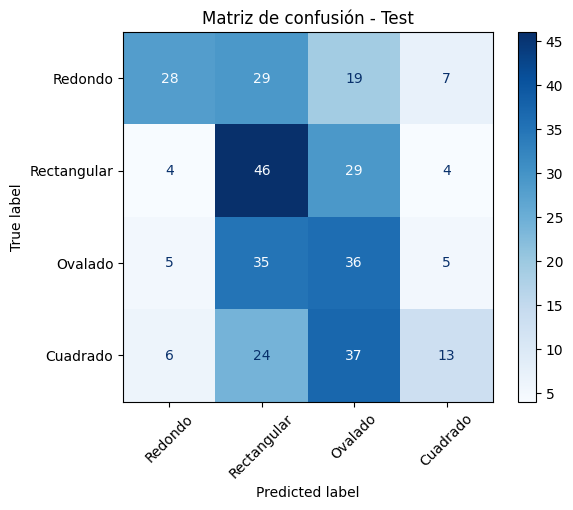

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

print(classification_report(y_real, y_pred, target_names=clases, digits=3))

matriz = confusion_matrix(y_real, y_pred)
ConfusionMatrixDisplay(matriz, display_labels=clases).plot(cmap='Blues', xticks_rotation=45)
plt.title('Matriz de confusión - Test')
plt.show()

---
## 5. Fine-tuning (descongelar las últimas capas)

### 5.1 Descongelar las últimas capas

Se descongela Inception v3 y se vuelven a congelar sus primeras 249 capas de 311. Esas capas detectan bordes y texturas simples, útiles para cualquier imagen; los últimos bloques, que combinan esas pistas en formas más complejas, se dejan libres para adaptarse a rostros.

In [ ]:
base.trainable = True
for capa in base.layers[:249]:
    capa.trainable = False

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy'])

entrenables = sum([int(np.prod(w.shape)) for w in modelo.trainable_weights])
print('Parámetros entrenables ahora:', entrenables)

Parámetros entrenables ahora: 11123076


### 5.2 Entrenamiento con fine-tuning

Mismo esquema de entrenamiento, con hasta 30 épocas, `patience=6` y otro archivo de guardado, para conservar el modelo base y poder compararlos.

In [ ]:
RUTA_MODELO_FT = '/content/drive/MyDrive/IA2/inception_rostros_finetuning.keras'

guardar_mejor_ft = tf.keras.callbacks.ModelCheckpoint(
    RUTA_MODELO_FT,
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1)

parar_temprano_ft = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=6,
    restore_best_weights=True)

historial_ft = modelo.fit(
    datos_train,
    validation_data=datos_val,
    epochs=30,
    callbacks=[guardar_mejor_ft, parar_temprano_ft])

Epoch 1/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step - accuracy: 0.3439 - loss: 1.4685
Epoch 1: val_accuracy improved from None to 0.58203, saving model to /content/drive/MyDrive/IA2/inception_rostros_finetuning.keras

Epoch 1: finished saving model to /content/drive/MyDrive/IA2/inception_rostros_finetuning.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 30s 454ms/step - accuracy: 0.3611 - loss: 1.4210 - val_accuracy: 0.5820 - val_loss: 1.0387
Epoch 2/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - accuracy: 0.4585 - loss: 1.1950
Epoch 2: val_accuracy did not improve from 0.58203
32/32 ━━━━━━━━━━━━━━━━━━━━ 15s 318ms/step - accuracy: 0.4403 - loss: 1.2053 - val_accuracy: 0.5742 - val_loss: 1.0392
Epoch 3/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step - accuracy: 0.5256 - loss: 1.0784
Epoch 3: val_accuracy did not improve from 0.58203
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 262ms/step - accuracy: 0.5479 - loss: 1.0672 - val_accuracy: 0.5625 - val_loss: 1.0181
Epoch 4/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step - accur

### 5.3 Curvas del fine-tuning


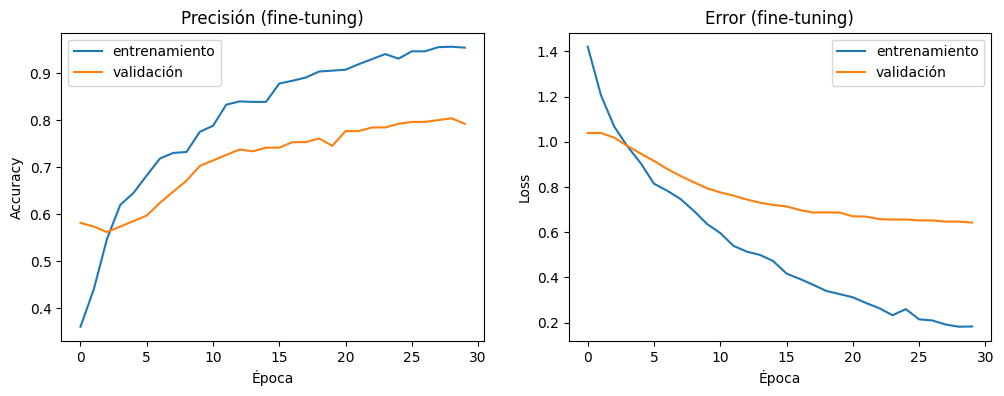

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(historial_ft.history['accuracy'], label='entrenamiento')
plt.plot(historial_ft.history['val_accuracy'], label='validación')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.title('Precisión (fine-tuning)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(historial_ft.history['loss'], label='entrenamiento')
plt.plot(historial_ft.history['val_loss'], label='validación')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.title('Error (fine-tuning)')
plt.legend()

plt.show()

### 5.4 Evaluación del modelo con fine-tuning en Test

In [ ]:
perdida_test, acc_test = modelo.evaluate(datos_test)
print('Accuracy en test:', round(acc_test, 4))

y_real = []
y_pred = []
for imagenes, etiquetas in datos_test:
    probabilidades = modelo.predict(imagenes, verbose=0)
    y_pred.extend(np.argmax(probabilidades, axis=1))
    y_real.extend(np.argmax(etiquetas.numpy(), axis=1))

print('Imágenes evaluadas:', len(y_real))

11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 175ms/step - accuracy: 0.5566 - loss: 1.4139
Accuracy en test: 0.5566
Imágenes evaluadas: 327


### 5.5 Matriz de confusión con fine-tuning

              precision    recall  f1-score   support

     Redondo      0.623     0.518     0.566        83
 Rectangular      0.522     0.711     0.602        83
     Ovalado      0.488     0.506     0.497        81
    Cuadrado      0.639     0.487     0.553        80

    accuracy                          0.557       327
   macro avg      0.568     0.556     0.554       327
weighted avg      0.568     0.557     0.555       327



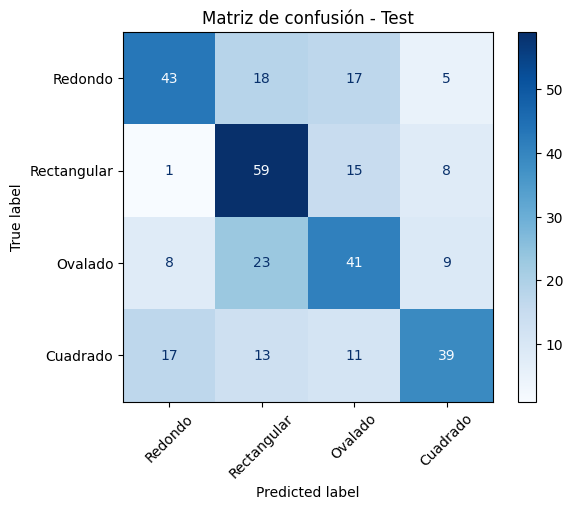

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

print(classification_report(y_real, y_pred, target_names=clases, digits=3))

matriz = confusion_matrix(y_real, y_pred)
ConfusionMatrixDisplay(matriz, display_labels=clases).plot(cmap='Blues', xticks_rotation=45)
plt.title('Matriz de confusión - Test')
plt.show()

---
## 6. Comparación de resultados

Todas las cifras de Test provienen de las evaluaciones de las secciones 4.5 y 5.4.

| Modelo | Mejor precisión en validación | Precisión en Test | F1 macro en Test |
|---|---|---|---|
| Base (Inception v3 congelada) | 60.9% | 37.6% | 0.366 |
| Con fine-tuning | 80.5% | 55.7% | 0.554 |

**Recall por clase en Test**

| Clase | Base | Con fine-tuning |
|---|---|---|
| Redondo | 33.7% | 51.8% |
| Rectangular | 55.4% | 71.1% |
| Ovalado | 44.4% | 50.6% |
| Cuadrado | 16.3% | 48.7% |

---
## 7. Prueba con foto de cliente

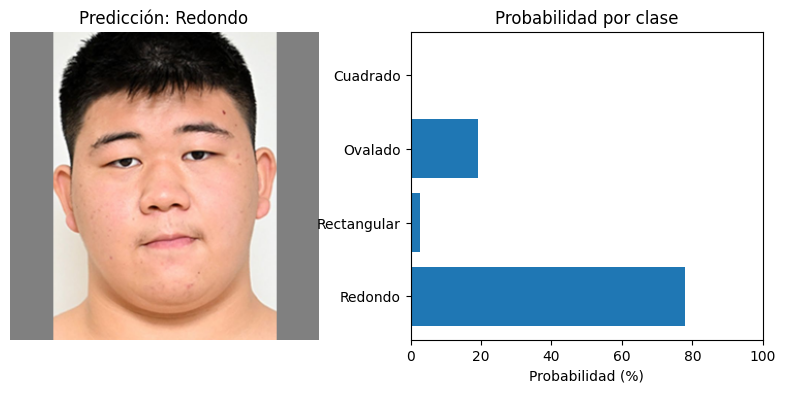

In [ ]:
import dlib
from PIL import ImageOps

detector = dlib.get_frontal_face_detector()
TAM = 299

def ampliar_caja(r, ancho_img, alto_img):
    ancho = r.right() - r.left()
    alto = r.bottom() - r.top()
    x1 = max(0, int(r.left() - 0.15 * ancho))
    x2 = min(ancho_img, int(r.right() + 0.15 * ancho))
    y1 = max(0, int(r.top() - 0.5 * alto))
    y2 = min(alto_img, int(r.bottom() + 0.30 * alto))
    return x1, y1, x2, y2

def predecir_rostro(ruta_foto):
    imagen = Image.open(ruta_foto).convert('RGB')
    arreglo = np.array(imagen)
    rostros = detector(arreglo, 1)

    if len(rostros) == 0:
        print('No se detectó ningún rostro en la foto')
        return

    r = max(rostros, key=lambda c: c.area())
    x1, y1, x2, y2 = ampliar_caja(r, imagen.width, imagen.height)
    cara = imagen.crop((x1, y1, x2, y2))
    cara = ImageOps.pad(cara, (TAM, TAM), color=(128, 128, 128))

    entrada = np.expand_dims(np.array(cara), axis=0).astype('float32')
    probabilidades = modelo.predict(entrada, verbose=0)[0]
    mejor = int(np.argmax(probabilidades))

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(cara)
    plt.title('Predicción: ' + clases[mejor])
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.barh(clases, probabilidades * 100)
    plt.xlim(0, 100)
    plt.xlabel('Probabilidad (%)')
    plt.title('Probabilidad por clase')
    plt.show()

predecir_rostro('/content/drive/MyDrive/IA2/Clientes/redondo.jpg')